In [ ]:
%pip install -q -U google-genai


In [ ]:
from google import genai
from google.colab import userdata

client = genai.Client(
    api_key=userdata.get("GEMINI_API_KEY")
)

response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents="Explain what Generative AI is in simple words."
)

print(response.text)

Imagine Generative AI as a **creative computer program**.

Instead of just *understanding* or *recognizing* things (like telling the difference between a cat and a dog), Generative AI can **make brand new things** on its own.

Think of it like this:

1.  **It learns by observing tons of examples:** It "reads" millions of books, "looks" at millions of pictures, or "listens" to millions of songs. Through this, it figures out the patterns, styles, and rules of how these things are put together.
2.  **Then, it creates something new:** When you give it a prompt (like "write a short story about a space explorer" or "draw a picture of a futuristic city with flying cars"), it uses all that learned knowledge to **generate something original** that fits your request.

It's not just copying; it's generating something novel that looks or sounds like it *could* have been made by a human, because it learned from so much human-made content.

**In short: It's AI that can create, not just analyze.**


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving project_risk_raw_dataset.csv to project_risk_raw_dataset.csv


In [ ]:
import pandas as pd

df = pd.read_csv("project_risk_raw_dataset.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 4000
Columns: 51


,Project_ID,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Methodology_Used,Team_Experience_Level,Past_Similar_Projects,...,Industry_Volatility,Client_Experience_Level,Change_Control_Maturity,Risk_Management_Maturity,Team_Colocation,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Seasonal_Risk_Factor,Risk_Level
0,PROJ_0001,Construction,32,1526276.55,32,9.70,16,Waterfall,Senior,3,...,Extreme,First-time,Basic,Basic,Fully Colocated,Good,10,5,1.0,High
1,PROJ_0002,Manufacturing,2,390790.15,9,2.72,9,Kanban,Mixed,0,...,Stable,Occasional,Advanced,Formal,Fully Remote,Poor,9,3,1.0,Low
2,PROJ_0003,Manufacturing,2,246674.76,6,2.04,7,Agile,Mixed,1,...,Stable,Regular,NaN,NaN,Hybrid,Good,5,1,1.0,Medium
3,PROJ_0004,IT,12,1427830.63,17,7.54,16,Scrum,Mixed,0,...,Extreme,Strategic,Formal,Basic,Hybrid,Basic,12,6,1.1,High
4,PROJ_0005,Construction,24,1696746.64,24,6.68,17,Hybrid,Junior,0,...,Moderate,Occasional,Basic,NaN,Partially Colocated,Basic,9,6,1.0,High


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("project_risk_raw_dataset.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 4000
Number of columns: 51


In [ ]:
print(df.columns.tolist())

['Project_ID', 'Project_Type', 'Team_Size', 'Project_Budget_USD', 'Estimated_Timeline_Months', 'Complexity_Score', 'Stakeholder_Count', 'Methodology_Used', 'Team_Experience_Level', 'Past_Similar_Projects', 'External_Dependencies_Count', 'Change_Request_Frequency', 'Project_Phase', 'Requirement_Stability', 'Team_Turnover_Rate', 'Vendor_Reliability_Score', 'Historical_Risk_Incidents', 'Communication_Frequency', 'Regulatory_Compliance_Level', 'Technology_Familiarity', 'Geographical_Distribution', 'Stakeholder_Engagement_Level', 'Schedule_Pressure', 'Budget_Utilization_Rate', 'Executive_Sponsorship', 'Funding_Source', 'Market_Volatility', 'Integration_Complexity', 'Resource_Availability', 'Priority_Level', 'Organizational_Change_Frequency', 'Cross_Functional_Dependencies', 'Previous_Delivery_Success_Rate', 'Technical_Debt_Level', 'Project_Manager_Experience', 'Org_Process_Maturity', 'Data_Security_Requirements', 'Key_Stakeholder_Availability', 'Tech_Environment_Stability', 'Contract_Type',

In [ ]:
df.head()

,Project_ID,Project_Type,Team_Size,Project_Budget_USD,Estimated_Timeline_Months,Complexity_Score,Stakeholder_Count,Methodology_Used,Team_Experience_Level,Past_Similar_Projects,...,Industry_Volatility,Client_Experience_Level,Change_Control_Maturity,Risk_Management_Maturity,Team_Colocation,Documentation_Quality,Project_Start_Month,Current_Phase_Duration_Months,Seasonal_Risk_Factor,Risk_Level
0,PROJ_0001,Construction,32,1526276.55,32,9.70,16,Waterfall,Senior,3,...,Extreme,First-time,Basic,Basic,Fully Colocated,Good,10,5,1.0,High
1,PROJ_0002,Manufacturing,2,390790.15,9,2.72,9,Kanban,Mixed,0,...,Stable,Occasional,Advanced,Formal,Fully Remote,Poor,9,3,1.0,Low
2,PROJ_0003,Manufacturing,2,246674.76,6,2.04,7,Agile,Mixed,1,...,Stable,Regular,NaN,NaN,Hybrid,Good,5,1,1.0,Medium
3,PROJ_0004,IT,12,1427830.63,17,7.54,16,Scrum,Mixed,0,...,Extreme,Strategic,Formal,Basic,Hybrid,Basic,12,6,1.1,High
4,PROJ_0005,Construction,24,1696746.64,24,6.68,17,Hybrid,Junior,0,...,Moderate,Occasional,Basic,NaN,Partially Colocated,Basic,9,6,1.0,High


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 51 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Project_ID                       4000 non-null   object 
 1   Project_Type                     4000 non-null   object 
 2   Team_Size                        4000 non-null   int64  
 3   Project_Budget_USD               4000 non-null   float64
 4   Estimated_Timeline_Months        4000 non-null   int64  
 5   Complexity_Score                 4000 non-null   float64
 6   Stakeholder_Count                4000 non-null   int64  
 7   Methodology_Used                 4000 non-null   object 
 8   Team_Experience_Level            4000 non-null   object 
 9   Past_Similar_Projects            4000 non-null   int64  
 10  External_Dependencies_Count      4000 non-null   int64  
 11  Change_Request_Frequency         4000 non-null   float64
 12  Project_Phase       

In [ ]:
missing_values = df.isnull().sum()

missing_report = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
]

print(missing_report)

                            Missing_Count  Missing_Percentage
Tech_Environment_Stability           2619               65.48
Change_Control_Maturity               780               19.50
Risk_Management_Maturity              791               19.78


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

print(
    "Duplicate Project IDs:",
    df["Project_ID"].duplicated().sum()
)

Duplicate rows: 0
Duplicate Project IDs: 0


In [ ]:
risk_counts = df["Risk_Level"].value_counts()

risk_percentages = (
    df["Risk_Level"]
    .value_counts(normalize=True) * 100
)

risk_summary = pd.DataFrame({
    "Project_Count": risk_counts,
    "Percentage": risk_percentages.round(2)
})

print(risk_summary)

            Project_Count  Percentage
Risk_Level                           
Medium               1396       34.90
High                 1036       25.90
Low                   806       20.15
Critical              762       19.05


In [ ]:
high_critical = df[
    df["Risk_Level"].isin(["High", "Critical"])
]

high_critical_percentage = (
    len(high_critical) / len(df) * 100
)

print(
    "High and Critical Risk:",
    round(high_critical_percentage, 2),
    "%"
)

High and Critical Risk: 44.95 %


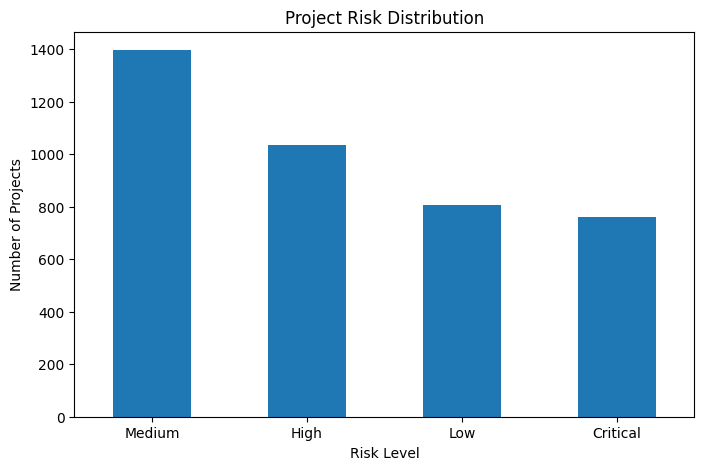

In [ ]:
risk_counts.plot(
    kind="bar",
    figsize=(8, 5),
    title="Project Risk Distribution"
)

plt.xlabel("Risk Level")
plt.ylabel("Number of Projects")
plt.xticks(rotation=0)
plt.show()

In [ ]:
risk_by_type = pd.crosstab(
    df["Project_Type"],
    df["Risk_Level"]
)

risk_by_type["High_Critical"] = (
    risk_by_type["High"] +
    risk_by_type["Critical"]
)

risk_by_type["High_Critical_Percentage"] = (
    risk_by_type["High_Critical"] /
    risk_by_type[
        ["Low", "Medium", "High", "Critical"]
    ].sum(axis=1) * 100
).round(2)

risk_by_type = risk_by_type.sort_values(
    "High_Critical_Percentage",
    ascending=False
)

print(risk_by_type)

Risk_Level     Critical  High  Low  Medium  High_Critical  \
Project_Type                                                
R&D                 211   196   38     143            407   
Construction        153   226  163     255            379   
Marketing            62   120   83     153            182   
IT                  238   313  305     525            551   
Manufacturing        57    99  104     158            156   
Healthcare           41    82  113     162            123   

Risk_Level     High_Critical_Percentage  
Project_Type                             
R&D                               69.22  
Construction                      47.55  
Marketing                         43.54  
IT                                39.90  
Manufacturing                     37.32  
Healthcare                        30.90  


In [ ]:
print("Total Project Budget:")
print(df["Project_Budget_USD"].sum())

print("\nAverage Project Budget:")
print(df["Project_Budget_USD"].mean())

print("\nAverage Budget Utilization:")
print(df["Budget_Utilization_Rate"].mean() * 100)

Total Project Budget:
4572126011.429999

Average Project Budget:
1143031.5028574998

Average Budget Utilization:
94.57275


In [ ]:
df["Estimated_Budget_Utilized"] = (
    df["Project_Budget_USD"] *
    df["Budget_Utilization_Rate"]
)

print(
    "Estimated Budget Utilized:",
    round(df["Estimated_Budget_Utilized"].sum(), 2)
)

Estimated Budget Utilized: 4323197004.53


In [ ]:
resource_summary = df[
    [
        "Team_Size",
        "Resource_Availability",
        "Vendor_Reliability_Score"
    ]
].describe()

print(resource_summary)

         Team_Size  Resource_Availability  Vendor_Reliability_Score
count  4000.000000            4000.000000               4000.000000
mean     15.388250               0.651695                  0.712087
std       9.220969               0.201163                  0.163418
min       2.000000               0.300000                  0.090000
25%       9.000000               0.480000                  0.600000
50%      13.000000               0.650000                  0.730000
75%      20.000000               0.820000                  0.840000
max      50.000000               1.000000                  1.000000


In [ ]:
governance_columns = [
    "Org_Process_Maturity",
    "Documentation_Quality",
    "Risk_Management_Maturity",
    "Change_Control_Maturity"
]

for column in governance_columns:
    print("\n", column)
    print(df[column].value_counts(dropna=False))


 Org_Process_Maturity
Org_Process_Maturity
Managed       1380
Defined       1267
Optimizing     759
Ad-hoc         594
Name: count, dtype: int64

 Documentation_Quality
Documentation_Quality
Basic        1392
Good         1366
Poor          622
Excellent     620
Name: count, dtype: int64

 Risk_Management_Maturity
Risk_Management_Maturity
Basic       1334
Formal      1332
NaN          791
Advanced     543
Name: count, dtype: int64

 Change_Control_Maturity
Change_Control_Maturity
Formal      1384
Basic       1308
NaN          780
Advanced     528
Name: count, dtype: int64


In [ ]:
for column in governance_columns:
    print("\nRisk analysis:", column)

    summary = pd.crosstab(
        df[column].fillna("Missing"),
        df["Risk_Level"],
        normalize="index"
    ) * 100

    print(summary.round(2))


Risk analysis: Org_Process_Maturity
Risk_Level            Critical   High    Low  Medium
Org_Process_Maturity                                
Ad-hoc                   42.93  34.01   4.04   19.02
Defined                  19.34  32.52  13.18   34.96
Managed                  15.51  23.77  22.39   38.33
Optimizing                6.32  12.38  40.32   40.97

Risk analysis: Documentation_Quality
Risk_Level             Critical   High    Low  Medium
Documentation_Quality                                
Basic                     18.10  26.51  18.61   36.78
Excellent                 15.32  22.90  28.87   32.90
Good                      19.40  24.45  20.35   35.80
Poor                      24.12  30.71  14.47   30.71

Risk analysis: Risk_Management_Maturity
Risk_Level                Critical   High    Low  Medium
Risk_Management_Maturity                                
Advanced                      4.60  11.05  41.44   42.91
Basic                        21.29  29.61  17.54   31.56
Formal        

In [ ]:
project_summary = {
    "Total_Projects": int(df["Project_ID"].nunique()),

    "Risk_Distribution": (
        df["Risk_Level"]
        .value_counts()
        .to_dict()
    ),

    "High_Critical_Risk_Percentage": round(
        high_critical_percentage, 2
    ),

    "Average_Project_Budget": round(
        df["Project_Budget_USD"].mean(), 2
    ),

    "Average_Budget_Utilization_Percentage": round(
        df["Budget_Utilization_Rate"].mean() * 100, 2
    ),

    "Estimated_Budget_Utilized": round(
        df["Estimated_Budget_Utilized"].sum(), 2
    ),

    "Average_Team_Size": round(
        df["Team_Size"].mean(), 2
    ),

    "Average_Resource_Availability_Percentage": round(
        df["Resource_Availability"].mean() * 100, 2
    ),

    "Average_Vendor_Reliability_Percentage": round(
        df["Vendor_Reliability_Score"].mean() * 100, 2
    ),

    "Average_Delivery_Success_Percentage": round(
        df["Previous_Delivery_Success_Rate"].mean() * 100, 2
    ),

    "Average_Historical_Risk_Incidents": round(
        df["Historical_Risk_Incidents"].mean(), 2
    )
}

print(project_summary)

{'Total_Projects': 4000, 'Risk_Distribution': {'Medium': 1396, 'High': 1036, 'Low': 806, 'Critical': 762}, 'High_Critical_Risk_Percentage': 44.95, 'Average_Project_Budget': np.float64(1143031.5), 'Average_Budget_Utilization_Percentage': np.float64(94.57), 'Estimated_Budget_Utilized': np.float64(4323197004.53), 'Average_Team_Size': np.float64(15.39), 'Average_Resource_Availability_Percentage': np.float64(65.17), 'Average_Vendor_Reliability_Percentage': np.float64(71.21), 'Average_Delivery_Success_Percentage': np.float64(75.04), 'Average_Historical_Risk_Incidents': np.float64(1.51)}


In [ ]:
import json

with open(
    "project_summary.json",
    "w"
) as file:
    json.dump(project_summary, file, indent=4)

print("Project summary saved successfully!")

Project summary saved successfully!


In [ ]:
from google.colab import files

files.download("project_summary.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from openai import OpenAI
from google.colab import userdata

# Retrieve API key securely
api_key = userdata.get("OPENAI_API_KEY")

# Create OpenAI client
client = OpenAI(api_key=api_key)

print("OpenAI API connection configured successfully!")

OpenAI API connection configured successfully!


In [ ]:
import json

print(json.dumps(project_summary, indent=4))


{
    "Total_Projects": 4000,
    "Risk_Distribution": {
        "Medium": 1396,
        "High": 1036,
        "Low": 806,
        "Critical": 762
    },
    "High_Critical_Risk_Percentage": 44.95,
    "Average_Project_Budget": 1143031.5,
    "Average_Budget_Utilization_Percentage": 94.57,
    "Estimated_Budget_Utilized": 4323197004.53,
    "Average_Team_Size": 15.39,
    "Average_Resource_Availability_Percentage": 65.17,
    "Average_Vendor_Reliability_Percentage": 71.21,
    "Average_Delivery_Success_Percentage": 75.04,
    "Average_Historical_Risk_Incidents": 1.51
}


In [ ]:
from google import genai
from google.colab import userdata

# Retrieve Gemini API key
gemini_api_key = userdata.get("GEMINI_API_KEY")

# Connect to Gemini
gemini_client = genai.Client(
    api_key=gemini_api_key
)

print("Gemini API connected successfully!")

Gemini API connected successfully!


In [ ]:
import json

prompt = f"""
You are an experienced Project Risk Management Analyst.

Analyze these calculated project statistics:

{json.dumps(project_summary, indent=2)}

Create a professional management report containing:

1. Executive Summary
2. Major Risk Observations
3. Financial Observations
4. Governance Observations
5. Recommended Management Actions

Rules:
- Use only the provided statistics.
- Do not invent numbers.
- Do not claim correlation proves causation.
- Distinguish estimated budget utilization from actual expenses.
- Do not claim to predict project failures.
- Give practical recommendations.
- Use simple professional English.

Return the response as valid JSON with these keys:
executive_summary
major_risk_observations
financial_observations
governance_observations
recommended_actions
"""

print("Prompt created!")

Prompt created!


In [ ]:
response = gemini_client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents=prompt,
    config={
        "response_mime_type": "application/json"
    }
)

print(response.text)

{
  "executive_summary": "This management report analyzes 4000 projects with an average budget of $1,143,031.50 and an estimated budget utilization of $4,323,197,004.53. The data reveals a high concentration of elevated risk levels, alongside significant resource and operational constraints that require structured management attention.",
  "major_risk_observations": "Out of 4000 total projects, the risk distribution consists of 762 Critical risks, 1036 High risks, 1396 Medium risks, and 806 Low risks. Combined, High and Critical risk categories account for 44.95% (1798 projects) of the portfolio. Additionally, projects report an average of 1.51 historical risk incidents.",
  "financial_observations": "The average project budget stands at $1,143,031.50 with an average budget utilization percentage of 94.57%. Based on the provided data, the estimated budget utilized across the portfolio reaches $4,323,197,004.53, representing estimated utilization rather than final audited actual expense

In [ ]:
ai_report = json.loads(response.text)

for section, content in ai_report.items():

    print("\n", section.upper())
    print("-" * 50)
    print(content)


 EXECUTIVE_SUMMARY
--------------------------------------------------
This management report analyzes 4000 projects with an average budget of $1,143,031.50 and an estimated budget utilization of $4,323,197,004.53. The data reveals a high concentration of elevated risk levels, alongside significant resource and operational constraints that require structured management attention.

 MAJOR_RISK_OBSERVATIONS
--------------------------------------------------
Out of 4000 total projects, the risk distribution consists of 762 Critical risks, 1036 High risks, 1396 Medium risks, and 806 Low risks. Combined, High and Critical risk categories account for 44.95% (1798 projects) of the portfolio. Additionally, projects report an average of 1.51 historical risk incidents.

 FINANCIAL_OBSERVATIONS
--------------------------------------------------
The average project budget stands at $1,143,031.50 with an average budget utilization percentage of 94.57%. Based on the provided data, the estimated budg

In [ ]:
ai_output = pd.DataFrame([{
    "Executive_Summary":
        ai_report["executive_summary"],

    "Major_Risk_Observations":
        ai_report["major_risk_observations"],

    "Financial_Observations":
        ai_report["financial_observations"],

    "Governance_Observations":
        ai_report["governance_observations"],

    "Recommended_Actions":
        ai_report["recommended_actions"]
}])

ai_output.to_csv(
    "AI_Project_Risk_Insights.csv",
    index=False,
    encoding="utf-8-sig"
)

print("AI report saved successfully!")

AI report saved successfully!


In [ ]:
from google.colab import files

files.download("AI_Project_Risk_Insights.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>